<a href="https://colab.research.google.com/github/Giomora-IA/IA--NOTA-AND-EJERCICIOS/blob/main/2_Playlist_spotyfy_Predecci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

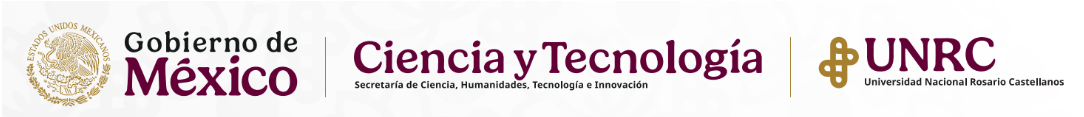

Práctica 2: Predicción de la popularidad de una canción de Spotify

Autor: Giovany David Morales Vasquez

GitHub: Giomora-IA

Fecha de actualización: Octubre-2026


# **Introducción**
En esta práctica se muestra un ejemplo sencillo de un problema de regresión para predecir la popularidad de una canción. Para ello se utilizarán las librerías TensorFlow, NumPy, Pandas, Scikit-learn y Matplotlib, junto con una base de datos obtenida de Spotify.

El objetivo es construir una red neuronal que aprenda la relación entre características musicales de una canción y su nivel de popularidad.

Conjunto de datos
La base de datos de Spotify contiene información de miles de canciones disponibles en la plataforma. Cada canción incluye atributos cuantitativos como:

Danceability: bailabilidad.

Energy: nivel de energía.

Loudness: volumen promedio en decibelios.

Speechiness: porcentaje de contenido hablado.

Acousticness: nivel de acústica.

Instrumentalness: nivel instrumental de la canción.

Valence: positividad emocional.

Tempo: ritmo de la canción, medido en beats por minuto.

Popularity: nivel de popularidad de la canción.

Duration_ms: duración en milisegundos.

Además, incluye datos cualitativos como el nombre del artista, el género musical y si la canción es explícita o no.

# DESARROLLO



Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1460/1460 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 573.2291 - mae: 19.5862 - val_loss: 485.8419 - val_mae: 18.2703
Epoch 2/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 483.0147 - mae: 18.1940 - val_loss: 477.9204 - val_mae: 18.0495
Epoch 3/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 476.4825 - mae: 18.0312 - val_loss: 474.6579 - val_mae: 18.0160
Epoch 4/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 471.3056 - mae: 17.8989 - val_loss: 469.9134 - val_mae: 17.7803
Epoch 5/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 467.4377 - mae: 17.7837 - val_loss: 466.5493 - val_mae: 17.7114
Epoch 6/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 464.4418 - mae: 17.6951 - val_loss: 464.6270 - val_mae: 17.7157
Epoch 7/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 461.7100 - mae: 17.6347 - val_loss: 464.4028 - val_mae: 17.6130
Epoch 8/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 459.1372 - mae: 17.5609 - val_loss: 462.6628 - val_mae: 17.6049
Epo

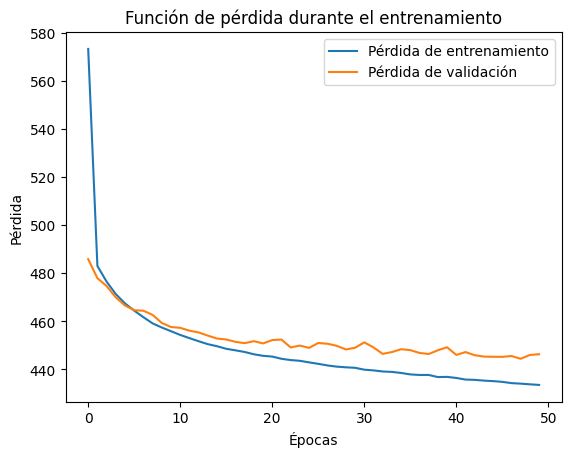

713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 443.6168 - mae: 17.0492
MAE en el conjunto test: 17.049224853515625


In [5]:
###Carga de la base de datos###

import pandas as pd

url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)

df

####Definición de parámetros y variable objetivo###

# Seleccionar características (features)
features = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'duration_ms',
]

X = df[features].values

# Target numérico
y = df['popularity'].values


#####División de los datos####

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
####Escalamiento de los datos####


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

###Definición de la red neuronal###

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

####Compilación del modelo#####
#Se utiliza el optimizador Adam con una tasa de aprendizaje de 0.001. Como función de pérdida se emplea el error cuadrático medio, adecuado para problemas de regresión.

from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)

model.compile(
    optimizer=adam_optimizer,
    loss='mse',
    metrics=['mae'],
)
###Entrenamiento del modelo##

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=50,
)

###Gráfica de la función de pérdida##
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


##Evaluación del modelo#####
loss, mae = model.evaluate(X_test, y_test)
print(f"MAE en el conjunto test: {mae}")

# REFERENCIAS


Predicción de popularidad de una canción | Notas de Redes Neuronales. (s. f.). Notas de Redes Neuronales. https://miguelevangelista.gitbook.io/notas-de-redes-neuronales/3.-redes-neuronales-arquitecturas-clasicas/3.4.-tipos-de-redes-neuronales/3.4.2.-red-neuronal-multicapa/ejemplos/prediccion-de-popularidad-de-una-cancion